# A2: GPU basics: bandwidth, matmul throughput, roofline

Three ideas, no deeper:
1. **Decode is limited by memory bandwidth.** Each generated token must read all ~2.2 GB of weights. We measure bandwidth once.
2. **Prefill is limited by compute.** Many tokens share one weight read, so the matmul units become the bottleneck. We measure matmul throughput once.
3. **Roofline.** A kernel does `FLOPs` of work and moves `bytes`. Its *arithmetic intensity* is `FLOPs / bytes`. Below the *ridge point* (peak FLOPs / peak bandwidth) it is memory-bound, above it compute-bound. For a decode matmul `(B, K) @ (K, N)` the weight dominates the bytes, so intensity is about `B`: **batching raises intensity**, and that is why it helps.

The T4 varies run to run (clocks, power, temperature), so we report **ranges** (min / median / max over repeated trials), not single numbers.

In [2]:
# Setup: clone or pull the repo, cd into it, put it on sys.path, install pytest.
import os, subprocess, sys

REPO_URL = "https://github.com/guptasameer112/tinyserve.git"
REPO_DIR = "/content/tinyserve"
if os.path.isdir(REPO_DIR):
    # Colab may hold untracked files (e.g. results written by a notebook) that clash with a pull.
    subprocess.run(["git", "-C", REPO_DIR, "fetch", "origin"], check=True)
    subprocess.run(["git", "-C", REPO_DIR, "reset", "--hard", "origin/main"], check=True)
else:
    subprocess.run(["git", "clone", REPO_URL, REPO_DIR], check=True)
os.chdir(REPO_DIR)
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pytest"], check=True)
print(subprocess.run(["git", "log", "--oneline", "-1"], capture_output=True, text=True).stdout)

2a5fe3e Notebooks: setup cell fetches and hard-resets instead of pull



In [3]:
import importlib, json
import torch
import tinyserve.roofline, tinyserve.gpu, tinyserve.plots
for module in (tinyserve.roofline, tinyserve.gpu, tinyserve.plots):
    importlib.reload(module)  # picks up repo edits after a git pull
from tinyserve.envinfo import collect_env

DEVICE = "cuda"
print(collect_env())
# Footnote: clocks and power explain run-to-run variation on the T4.
print(subprocess.run(
    ["nvidia-smi", "--query-gpu=name,clocks.sm,clocks.max.sm,power.draw,power.limit,temperature.gpu", "--format=csv"],
    capture_output=True, text=True).stdout)

{'python': '3.13.16', 'platform': 'Linux-6.6.122+-x86_64-with-glibc2.39', 'git_sha': '2a5fe3e', 'gpu': 'Tesla T4', 'torch': '2.11.0+cu130', 'cuda': '13.0', 'transformers': '5.20.2'}
name, clocks.current.sm [MHz], clocks.max.sm [MHz], power.draw [W], power.limit [W], temperature.gpu
Tesla T4, 585 MHz, 1590 MHz, 32.98 W, 70.00 W, 71



## 1. Memory bandwidth
We time a device-to-device copy of `S` bytes. It reads `S` and writes `S`, so traffic is `2S`. Small buffers fit in the T4's ~4 MiB L2 cache and look unrealistically fast; large buffers measure the real GDDR6 bandwidth. Datasheet peak: **320 GB/s**.

In [4]:
from tinyserve.gpu import measure_bandwidth_curve
from tinyserve.roofline import T4_DATASHEET

bandwidth_rows = measure_bandwidth_curve([1, 4, 16, 64, 256, 1024], DEVICE)
for row in bandwidth_rows:
    stats = row["gb_s"]
    print(f"{row['size_mib']:>5} MiB  {stats['min']:7.1f} / {stats['median']:7.1f} / {stats['max']:7.1f} GB/s  (min/median/max)")

# Large buffers only: these are not served by L2.
MEASURED_BANDWIDTH = max(r["gb_s"]["median"] for r in bandwidth_rows if r["size_mib"] >= 64) * 1e9
print(f"\nmeasured bandwidth: {MEASURED_BANDWIDTH / 1e9:.0f} GB/s  ({MEASURED_BANDWIDTH / T4_DATASHEET['bandwidth_bytes_per_s']:.0%} of the 320 GB/s datasheet)")

    1 MiB    117.7 /   152.7 /   191.3 GB/s  (min/median/max)
    4 MiB    215.6 /   218.2 /   219.8 GB/s  (min/median/max)
   16 MiB    234.6 /   237.1 /   237.5 GB/s  (min/median/max)
   64 MiB    240.6 /   240.7 /   240.9 GB/s  (min/median/max)
  256 MiB    233.6 /   233.9 /   242.9 GB/s  (min/median/max)
 1024 MiB    218.4 /   233.1 /   233.3 GB/s  (min/median/max)

measured bandwidth: 241 GB/s  (75% of the 320 GB/s datasheet)


## 2. Matmul throughput
A big square matmul does `2*n^3` FLOPs on `3*n^2` elements, so its intensity grows with `n`: it is compute-bound. FP16 uses tensor cores (datasheet **65 TFLOPS**); FP32 does not (datasheet **8.1 TFLOPS**). Real T4s land well below the FP16 peak because of power and clock limits. Short runs can briefly run faster (**burst**) before the card hits its 70 W limit and the clock drops, so we use the largest matmul as the **sustained** number and treat that as the roof.

In [5]:
from tinyserve.gpu import measure_matmul_curve

fp16_rows = measure_matmul_curve([512, 1024, 2048, 4096, 8192], DEVICE, torch.float16)
fp32_rows = measure_matmul_curve([1024, 2048, 4096], DEVICE, torch.float32)
for name, rows in (("fp16", fp16_rows), ("fp32", fp32_rows)):
    for row in rows:
        stats = row["tflops"]
        print(f"{name} n={row['size']:>5}  intensity {row['intensity']:7.1f}  {stats['min']:5.1f} / {stats['median']:5.1f} / {stats['max']:5.1f} TFLOPS")

MEASURED_FP16_BURST = max(r["tflops"]["median"] for r in fp16_rows) * 1e12  # short bursts, before the T4 throttles
MEASURED_FP16_FLOPS = fp16_rows[-1]["tflops"]["median"] * 1e12  # sustained: largest matmul, used as the roof
MEASURED_FP32_FLOPS = fp32_rows[-1]["tflops"]["median"] * 1e12
print(f"\nfp16 burst {MEASURED_FP16_BURST / 1e12:.1f} TFLOPS, sustained {MEASURED_FP16_FLOPS / 1e12:.1f} TFLOPS ({MEASURED_FP16_FLOPS / T4_DATASHEET['fp16_flops']:.0%} of datasheet), "
      f"fp32 {MEASURED_FP32_FLOPS / 1e12:.1f} TFLOPS ({MEASURED_FP32_FLOPS / T4_DATASHEET['fp32_flops']:.0%})")

fp16 n=  512  intensity   170.7    7.8 /   9.1 /   9.6 TFLOPS
fp16 n= 1024  intensity   341.3   36.9 /  37.3 /  37.5 TFLOPS
fp16 n= 2048  intensity   682.7   13.8 /  17.1 /  42.5 TFLOPS
fp16 n= 4096  intensity  1365.3   18.8 /  18.9 /  18.9 TFLOPS
fp16 n= 8192  intensity  2730.7   19.3 /  19.5 /  20.0 TFLOPS
fp32 n= 1024  intensity   170.7    2.8 /   3.0 /   3.5 TFLOPS
fp32 n= 2048  intensity   341.3    3.0 /   3.0 /   3.0 TFLOPS
fp32 n= 4096  intensity   682.7    3.0 /   3.1 /   3.1 TFLOPS

measured peak: fp16 37.3 TFLOPS (57% of datasheet), fp32 3.1 TFLOPS (38%)


## 3. The roofline and the decode ceiling
- **Ridge point** = peak FLOPs / peak bandwidth: the intensity needed to keep the matmul units busy.
- **Decode ceiling** at batch 1 = bandwidth / weight bytes. This ignores the KV cache and overheads, so real decode is slower. TinyLlama FP16 weights are 2,200,096,768 bytes (from the A1 results).

In [6]:
from tinyserve.roofline import ridge_point, decode_tokens_per_s_ceiling

WEIGHT_BYTES = json.load(open("results/A1_shapes.json"))["data"]["weight_bytes"]
print("ridge, datasheet:", round(ridge_point(T4_DATASHEET["fp16_flops"], T4_DATASHEET["bandwidth_bytes_per_s"])), "FLOPs/byte")
print("ridge, measured :", round(ridge_point(MEASURED_FP16_FLOPS, MEASURED_BANDWIDTH)), "FLOPs/byte")
print()
for batch in (1, 8, 32, 64):
    ceiling = decode_tokens_per_s_ceiling(WEIGHT_BYTES, MEASURED_BANDWIDTH, batch)
    print(f"batch {batch:>3}: memory-bound decode ceiling {ceiling:7.0f} tokens/s total, {ceiling / batch:6.1f} tokens/s per sequence")

ridge, datasheet: 203 FLOPs/byte
ridge, measured : 155 FLOPs/byte

batch   1: memory-bound decode ceiling     109 tokens/s total,  109.4 tokens/s per sequence
batch   8: memory-bound decode ceiling     875 tokens/s total,  109.4 tokens/s per sequence
batch  32: memory-bound decode ceiling    3501 tokens/s total,  109.4 tokens/s per sequence
batch  64: memory-bound decode ceiling    7002 tokens/s total,  109.4 tokens/s per sequence


## 4. Why batching helps: one decode-sized matmul
TinyLlama's MLP up-projection is `(B, 2048) @ (2048, 5632)` in FP16. The weight is 23 MB, so it is read from memory (it does not fit in L2). Watch what happens as `B` grows: time stays almost flat while memory-bound, so rows per second scale nearly linearly with `B`. Once intensity passes the ridge point, time starts to grow.

In [7]:
from tinyserve.gpu import measure_decode_curve

decode_rows = measure_decode_curve([1, 2, 4, 8, 16, 32, 64, 128, 256, 512], 2048, 5632, DEVICE, torch.float16)
print(f"{'B':>4} {'ms':>8} {'intensity':>10} {'GB/s':>8} {'TFLOPS':>8} {'rows/s':>10}")
for row in decode_rows:
    print(f"{row['batch']:>4} {row['median_ms']:8.4f} {row['intensity']:10.1f} {row['gb_s']:8.1f} {row['tflops']:8.2f} {row['rows_per_s']:10.0f}")

   B       ms  intensity     GB/s   TFLOPS     rows/s
   1   0.0990        1.0    233.1     0.23      10099
   2   0.1010        2.0    228.8     0.46      19809
   4   0.1057        4.0    218.8     0.87      37836
   8   0.1102        8.0    210.5     1.68      72617
  16   0.1140       15.8    204.6     3.24     140386
  32   0.1148       31.3    205.2     6.43     278726
  64   0.1227       61.4    196.1    12.04     521737
 128   0.2006      117.9    124.8    14.72     638086
 256   0.3918      218.7     68.9    15.07     653416
 512   0.6765      381.8     45.7    17.46     756886


## 5. The roofline diagram (code, not a screenshot)
Black line: the roofs using our *measured* peaks. Points: big matmuls sit on the flat compute roof; decode-sized matmuls climb the slanted memory roof as `B` grows.

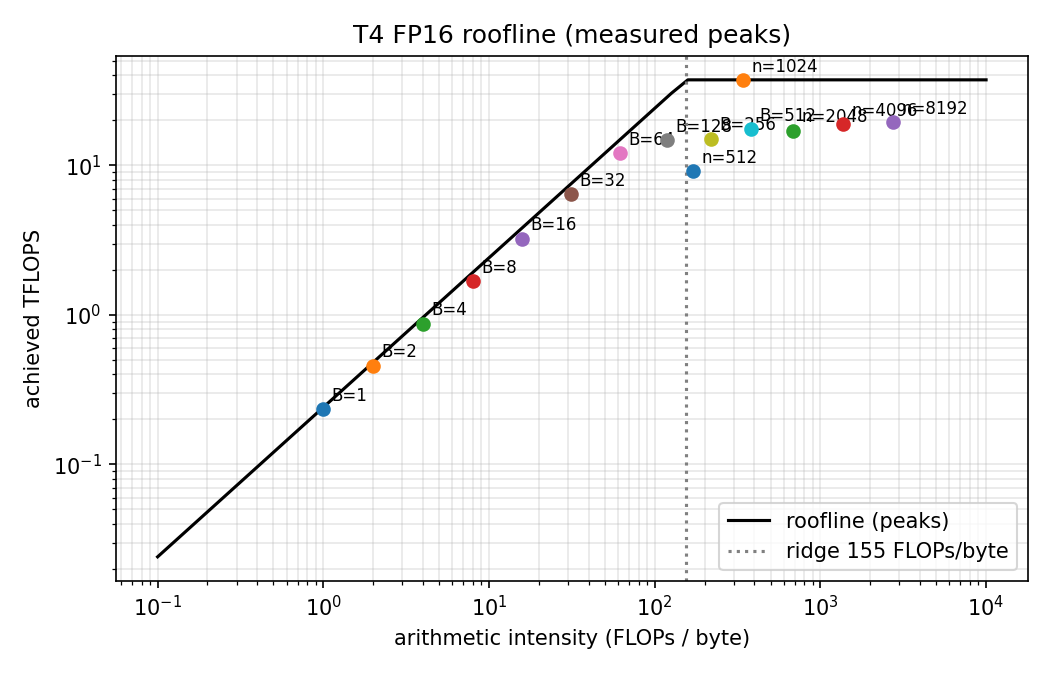

In [8]:
from IPython.display import Image, display
from tinyserve.plots import plot_roofline

points = [(f"B={r['batch']}", r["intensity"], r["tflops"] * 1e12) for r in decode_rows]
points += [(f"n={r['size']}", r["intensity"], r["tflops"]["median"] * 1e12) for r in fp16_rows]
os.makedirs("results", exist_ok=True)
plot_path = plot_roofline(MEASURED_FP16_FLOPS, MEASURED_BANDWIDTH, points, "results/A2_roofline.png",
                          title="T4 FP16 roofline (measured sustained peaks)", burst_flops=MEASURED_FP16_BURST)
display(Image(plot_path))

## 6. Save results and run the tests

In [9]:
from tinyserve.envinfo import save_result

saved_path = save_result("A2_gpu", {
    "datasheet": T4_DATASHEET,
    "measured_bandwidth_gb_s": MEASURED_BANDWIDTH / 1e9,
    "measured_fp16_tflops": MEASURED_FP16_FLOPS / 1e12,
    "measured_fp16_burst_tflops": MEASURED_FP16_BURST / 1e12,
    "measured_fp32_tflops": MEASURED_FP32_FLOPS / 1e12,
    "bandwidth_curve": bandwidth_rows,
    "matmul_fp16": fp16_rows,
    "matmul_fp32": fp32_rows,
    "decode_matmul_2048x5632_fp16": decode_rows,
})
print(saved_path)
print(json.dumps(json.load(open(saved_path))["data"]["decode_matmul_2048x5632_fp16"][:2], indent=1))

/content/tinyserve/results/A2_gpu.json
[
 {
  "batch": 1,
  "median_ms": 0.09902080297470092,
  "intensity": 0.9993346049771548,
  "gb_s": 233.12305401015377,
  "tflops": 0.23296793509030495,
  "rows_per_s": 10098.888010991917
 },
 {
  "batch": 2,
  "median_ms": 0.10096640586853027,
  "intensity": 1.9973401897331324,
  "gb_s": 228.78294816275854,
  "tflops": 0.45695737709110956,
  "rows_per_s": 19808.568828370768
 }
]


In [10]:
result = subprocess.run([sys.executable, "-m", "pytest", "tests/test_a2_roofline.py", "-v"], capture_output=True, text=True)
print(result.stdout[-3500:], result.stderr[-1000:])

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/tinyserve
configfile: pyproject.toml
plugins: typeguard-4.6.0, anyio-4.15.1, langsmith-0.14.11, platformdirs-4.13.5
collecting ... collected 9 items

tests/test_a2_roofline.py::test_matmul_flops_and_bytes PASSED            [ 11%]
tests/test_a2_roofline.py::test_decode_matmul_intensity_is_about_batch FAILED [ 22%]
tests/test_a2_roofline.py::test_ridge_and_attainable PASSED              [ 33%]
tests/test_a2_roofline.py::test_decode_ceiling_scales_with_batch PASSED  [ 44%]
tests/test_a2_roofline.py::test_summarize_reports_a_range PASSED         [ 55%]
tests/test_a2_roofline.py::test_t4_datasheet_values PASSED               [ 66%]
tests/test_a2_roofline.py::test_bandwidth_is_positive_and_below_datasheet PASSED [ 77%]
tests/test_a2_roofline.py::test_fp16_matmul_beats_fp32_matmul PASSED     

In [11]:
# Print the full results file so it can be copied into the repo from the saved notebook.
print(open(saved_path).read())

{
  "name": "A2_gpu",
  "timestamp_utc": "2026-10-25T06:30:17Z",
  "env": {
    "python": "3.13.16",
    "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
    "git_sha": "2a5fe3e",
    "gpu": "Tesla T4",
    "torch": "2.11.0+cu130",
    "cuda": "13.0",
    "transformers": "5.20.2"
  },
  "data": {
    "datasheet": {
      "bandwidth_bytes_per_s": 320000000000.0,
      "fp16_flops": 65000000000000.0,
      "fp32_flops": 8100000000000.0
    },
    "measured_bandwidth_gb_s": 240.71853619741387,
    "measured_fp16_tflops": 37.328326721275076,
    "measured_fp32_tflops": 3.067125923366315,
    "bandwidth_curve": [
      {
        "size_mib": 1,
        "gb_s": {
          "min": 117.71172187230383,
          "median": 152.74675934307518,
          "max": 191.34598525577414,
          "n": 7
        }
      },
      {
        "size_mib": 4,
        "gb_s": {
          "min": 215.62328153317412,
          "median": 218.21692373509256,
          "max": 219.79038699794694,
          "n": 7
  